# Analyse de l'influence des prétraitements

Les résultats sont issus des évaluations automatisées et historisées dans MLflow. Aucune nouvelle inférence n'est nécessaire pour cette analyse.

## Chargement des résultats

Les données utilisées dans ce notebook proviennent des fichiers CSV et JSON générés par le script d'évaluation.

Les trois expérimentations sont identifiées explicitement afin de garantir la reproductibilité de l'analyse.

In [5]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Identification de la racine du projet
RACINE_PROJET = Path.cwd()

if RACINE_PROJET.name == "notebooks":
    RACINE_PROJET = RACINE_PROJET.parent

DOSSIER_RESULTATS = (RACINE_PROJET / "evaluation" / "resultats")
DOSSIER_IMAGES = (RACINE_PROJET / "datasets" / "benchmark_v1" / "images")

print("Racine du projet :", RACINE_PROJET)
print("Dossier résultats accessible :", DOSSIER_RESULTATS.exists())
print("Dossier images accessible :", DOSSIER_IMAGES.exists())

Racine du projet : c:\Users\Lily\Desktop\YNOV\INDUS IA\Vision par ordinateur
Dossier résultats accessible : True
Dossier images accessible : True


In [6]:
EXPERIMENTATIONS = {
    "center_crop": ("pytorch_fp32_benchmark_v1_center_crop_20261120_122355_713133"),
    "resize": ("pytorch_fp32_benchmark_v1_resize_20261120_122556_341642"),
    "padding": ("pytorch_fp32_benchmark_v1_padding_20261120_122638_551917")
}

In [7]:
evaluations = {}

for methode, nom_dossier in EXPERIMENTATIONS.items():
    dossier = DOSSIER_RESULTATS / nom_dossier
    evaluations[methode] = {
        "configuration": json.loads(
            (dossier / "configuration.json").read_text(
                encoding="utf-8"
            )
        ),
        "metrics": json.loads(
            (dossier / "metrics.json").read_text(
                encoding="utf-8"
            )
        ),
        "predictions": pd.read_csv(
            dossier / "predictions.csv"
        ),
        "metrics_classes": pd.read_csv(
            dossier / "metrics_par_classe.csv"
        ),
        "matrice_confusion": pd.read_csv(
            dossier / "matrice_confusion.csv",
            index_col=0
        )
    }

    print(
        f"{methode} : "
        f"{len(evaluations[methode]['predictions'])} prédictions chargées"
    )

center_crop : 200 prédictions chargées
resize : 200 prédictions chargées
padding : 200 prédictions chargées


In [8]:
display(evaluations["resize"]["predictions"].head())

,filename,label_reel,label_predit,score_top1,top5_predictions,top1_correct,top5_correct
0,6296.png,CHEST,CHEST,0.4708,"[{""classe"": ""CHEST"", ""libelle"": ""Thorax"", ""sco...",True,True
1,13732.png,CHEST,CHEST,0.8581,"[{""classe"": ""CHEST"", ""libelle"": ""Thorax"", ""sco...",True,True
2,10724.png,CHEST,SHOULDER,0.3427,"[{""classe"": ""SHOULDER"", ""libelle"": ""\u00c9paul...",False,False
3,8089.png,CHEST,CHEST,0.9071,"[{""classe"": ""CHEST"", ""libelle"": ""Thorax"", ""sco...",True,True
4,18827.png,CHEST,CHEST,0.8625,"[{""classe"": ""CHEST"", ""libelle"": ""Thorax"", ""sco...",True,True


## Comparaison des performances globales

### Choix des métriques

Les métriques retenues permettent d'évaluer la qualité de la classification sous différents angles.

- **Accuracy Top-1** : capacité du modèle à identifier précisément la région anatomique attendue.
- **Accuracy Top-5** : capacité du modèle à proposer la bonne région parmi ses cinq premières prédictions.
- **Précision macro** : fiabilité moyenne des classifications par région anatomique.
- **Rappel macro** : capacité moyenne à reconnaître les images de chaque région anatomique.
- **F1-score macro** : équilibre entre précision et rappel.

Dans le contexte de l'imagerie médicale, plusieurs régions anatomiques peuvent être visibles sur une même radiographie.

L'Accuracy Top-5 présente donc un intérêt particulier dans une logique d'assistance à la classification, tandis que l'Accuracy Top-1 reste importante pour une catégorisation automatique.

Les moyennes macro permettent d'accorder la même importance à chaque classe évaluée.

In [9]:
NOMS_METHODES = {
    "center_crop": "Center Crop",
    "resize": "Resize",
    "padding": "Padding"
}

NOMS_METRIQUES = {
    "accuracy_top1": "Accuracy Top-1",
    "accuracy_top5": "Accuracy Top-5",
    "precision_macro": "Précision macro",
    "rappel_macro": "Rappel macro",
    "f1_macro": "F1-score macro"
}

comparatif = pd.DataFrame({
    NOMS_METHODES[methode]: evaluation["metrics"]
    for methode, evaluation in evaluations.items()
}).T

comparatif = comparatif[
    list(NOMS_METRIQUES.keys())
].rename(columns=NOMS_METRIQUES)

display(
    comparatif.style
    .format("{:.2%}")
    .highlight_max(axis=0, color="#c5e8ce")
)

,Accuracy Top-1,Accuracy Top-5,Précision macro,Rappel macro,F1-score macro
Center Crop,41.50%,83.00%,63.24%,41.50%,46.81%
Resize,57.50%,85.00%,81.49%,57.50%,65.01%
Padding,40.00%,84.50%,81.13%,40.00%,49.45%


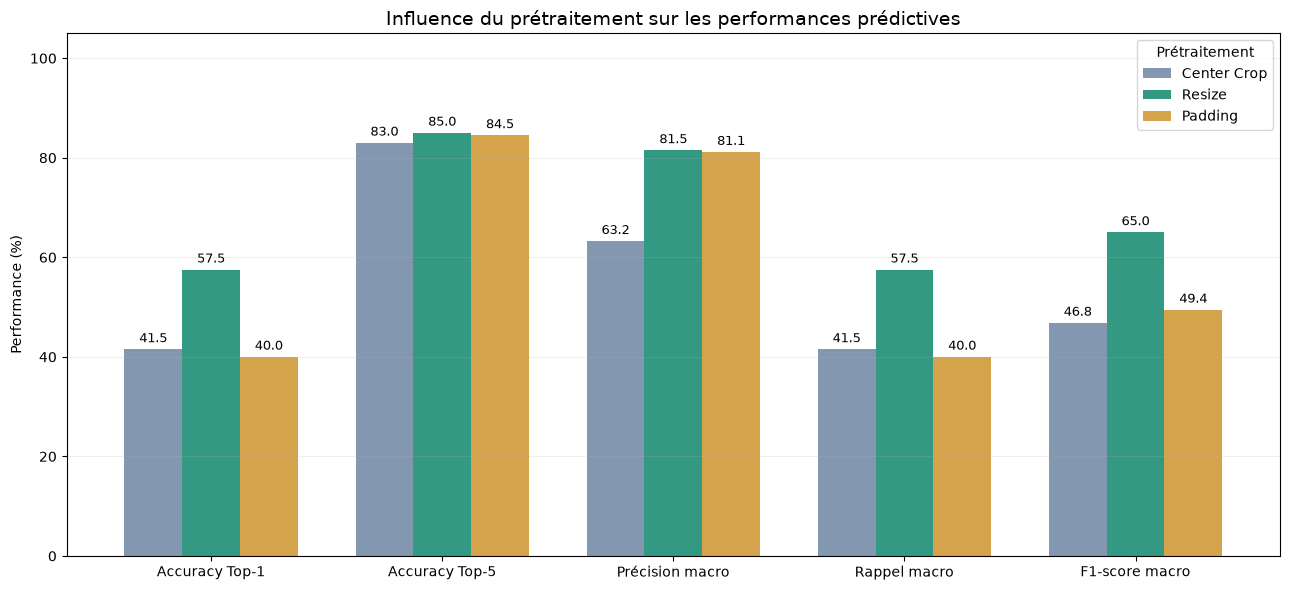

In [10]:
COULEURS = ["#8497B0", "#349982", "#D5A34C"]

ax = (comparatif.T * 100).plot(
    kind="bar",
    figsize=(13, 6),
    color=COULEURS,
    width=0.75
)

ax.set_title(
    "Influence du prétraitement sur les performances prédictives",
    fontsize=14
)

ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 105)
ax.set_xlabel("")
ax.legend(title="Prétraitement")
ax.grid(axis="y", alpha=0.2)

for conteneur in ax.containers:
    ax.bar_label(
        conteneur,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
gains = (
    comparatif.subtract(
        comparatif.loc["Center Crop"],
        axis="columns"
    ) * 100
)

display(
    gains.style.format("{:+.2f} pts")
)

,Accuracy Top-1,Accuracy Top-5,Précision macro,Rappel macro,F1-score macro
Center Crop,+0.00 pts,+0.00 pts,+0.00 pts,+0.00 pts,+0.00 pts
Resize,+16.00 pts,+2.00 pts,+18.25 pts,+16.00 pts,+18.19 pts
Padding,-1.50 pts,+1.50 pts,+17.90 pts,-1.50 pts,+2.63 pts


### Analyse des résultats

Le redimensionnement direct (Resize) présente les meilleures
performances globales sur le dataset de référence.

Par rapport au Center Crop :

- L'Accuracy Top-1 progresse de 16 points.
- L'Accuracy Top-5 progresse de 2 points.
- Le F1-score macro progresse de 18,20 points.

Ces améliorations sont obtenues sans modification des poids
du modèle ni réentraînement.

Le prétraitement avec Padding, malgré la conservation des
proportions de l'image, n'améliore pas l'Accuracy Top-1.

Plusieurs hypothèses peuvent expliquer ces résultats :

- Perte d'informations anatomiques avec le Center Crop.
- Conservation du contexte anatomique avec le Resize.
- Réduction de la surface utile de l'image avec le Padding.
- Sensibilité du modèle aux transformations géométriques.

Ces hypothèses seront étudiées lors de l'analyse visuelle
des images prétraitées.

Les résultats restent spécifiques au dataset benchmark_v1
et nécessiteraient une validation sur un dataset indépendant
pour confirmer leur généralisation.